## Parametric VaR and Expected Shortfall

- **Portfolio:** USD 5,000 — 50% AVGO, 25% QQQ, 15% MRVL and 10% TSLA
- **Time horizon:** 5 trading days
- **Lookback period:** 5 years
- **Confidence levels:** 90%, 95% and 99%

The mean and standard deviation are estimated directly from five years of rolling five-day portfolio returns. Assuming these returns follow a normal distribution, the estimated parameters are used to calculate Parametric VaR and Expected Shortfall at each confidence level.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import norm

Step1.
Define the Basic Variables that I am going to use in the analysis
The portfolio I construct is my current equity holdings

In [2]:
tickers = ["QQQ", "MRVL", "TSLA", "AVGO"]
weights = np.array([0.25, 0.15, 0.1, 0.5])
portfolio_value = 5000
time_horizon = 5 #in days

Step2.
Read data from our clean csv file

In [3]:
log_returns = pd.read_csv("cleaned_log_returns.csv", index_col="Date", parse_dates=True)
log_returns = log_returns.reindex(columns=tickers)
display(log_returns.head())

,QQQ,MRVL,TSLA,AVGO
Date,,,,
2021-11-15,-0.000228,-0.007650,-0.019573,0.004517
2021-11-16,0.007096,0.012267,0.039984,0.005288
2021-11-17,0.000528,-0.002441,0.031984,0.001529
2021-11-18,0.010308,0.020298,0.006745,0.009035
2021-11-19,0.005560,-0.007614,0.036432,-0.010651


Step3. 
Compute Rolling 5-day Portfolio Returns
--> Therefore calculate out the estimated mean and variance for VaR

In [4]:
portfolio_returns = log_returns.dot(weights)
portfolio_returns_5d =portfolio_returns.rolling(window=time_horizon).sum().dropna()
mean_5d = portfolio_returns_5d.mean()
std_5d = portfolio_returns_5d.std()

Step4.
Assume that returns follows normal distribution
And it is efficient to use the sample result to estimate the real parameters

In [5]:
confidence_levels = [0.90, 0.95, 0.99]
var_values = []
es_values = []

for confidence_level in confidence_levels:
    var = portfolio_value * (norm.ppf(confidence_level) * std_5d - mean_5d)
    var_values.append(var)
    z_score = norm.ppf(confidence_level)
    es = portfolio_value * (norm.pdf(z_score) * std_5d / (1 - confidence_level) - mean_5d)
    es_values.append(es)

Step5.
Plot the diagram

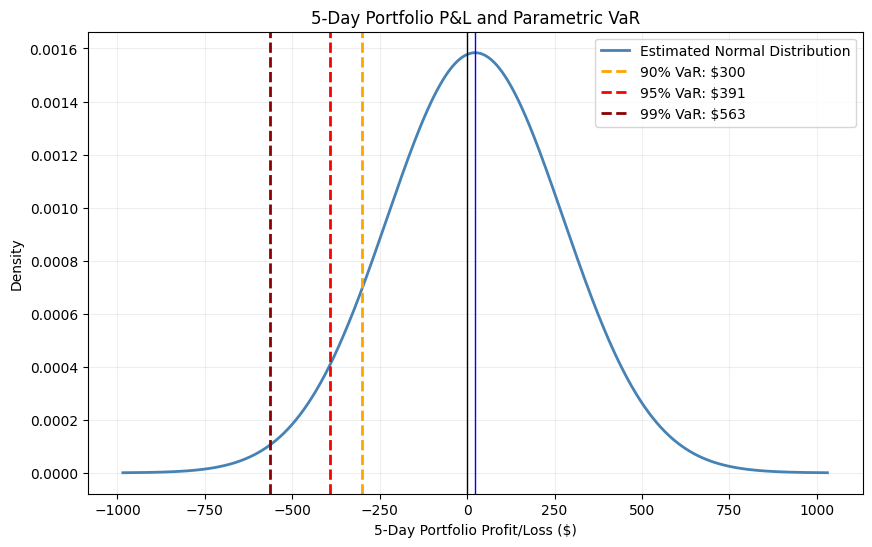

In [6]:
pnl_5d = portfolio_returns_5d * portfolio_value
mean_pnl_5d = mean_5d * portfolio_value
std_pnl_5d = std_5d * portfolio_value

x = np.linspace(
    mean_pnl_5d - 4 * std_pnl_5d,
    mean_pnl_5d + 4 * std_pnl_5d,
    10000
)
y = norm.pdf(
    x,
    loc=mean_pnl_5d,
    scale=std_pnl_5d
)
plt.figure(figsize=(10, 6))
plt.plot(
    x,
    y,
    color="steelblue",
    linewidth=2,
    label="Estimated Normal Distribution"
)

colors = ["orange", "red", "darkred"]
for confidence_level, var, color in zip(
    confidence_levels,
    var_values,
    colors
):
    plt.axvline(
        x=-var,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{confidence_level:.0%} VaR: ${var:,.0f}"
    )
plt.axvline(x=mean_pnl_5d, color="blue", linewidth=1)
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("5-Day Portfolio Profit/Loss ($)")
plt.ylabel("Density")
plt.title("5-Day Portfolio P&L and Parametric VaR")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

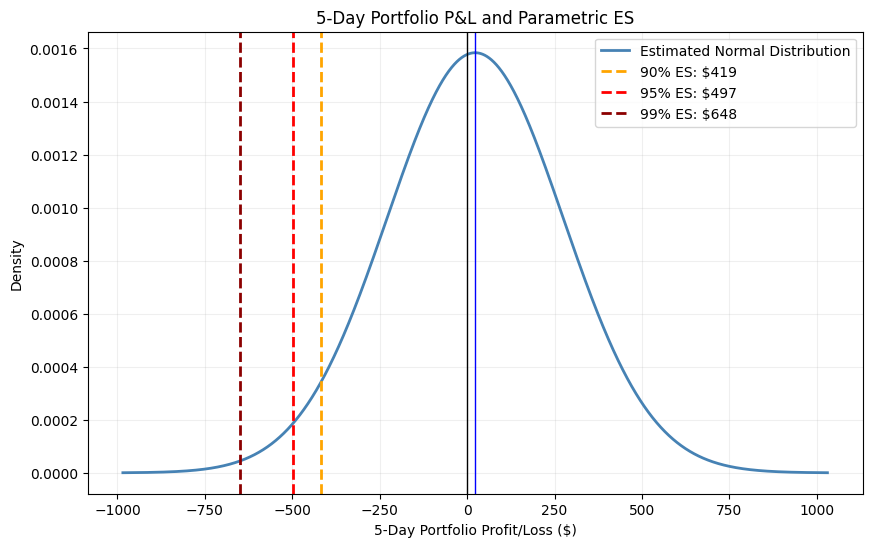

In [7]:
pnl_5d = portfolio_returns_5d * portfolio_value
mean_pnl_5d = mean_5d * portfolio_value
std_pnl_5d = std_5d * portfolio_value

x = np.linspace(
    mean_pnl_5d - 4 * std_pnl_5d,
    mean_pnl_5d + 4 * std_pnl_5d,
    10000
)
y = norm.pdf(
    x,
    loc=mean_pnl_5d,
    scale=std_pnl_5d
)
plt.figure(figsize=(10, 6))
plt.plot(
    x,
    y,
    color="steelblue",
    linewidth=2,
    label="Estimated Normal Distribution"
)

colors = ["orange", "red", "darkred"]
for confidence_level, es, color in zip(
    confidence_levels,
    es_values,
    colors
):
    plt.axvline(
        x=-es,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{confidence_level:.0%} ES: ${es:,.0f}"
    )
plt.axvline(x=mean_pnl_5d, color="blue", linewidth=1)
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("5-Day Portfolio Profit/Loss ($)")
plt.ylabel("Density")
plt.title("5-Day Portfolio P&L and Parametric ES")
plt.legend()
plt.grid(alpha=0.2)
plt.show()